In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [11]:
X, y_true = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)

print("Dataset shape:", X.shape)
print("First 5 rows:\n", X[:5])

Dataset shape: (300, 2)
First 5 rows:
 [[-7.43086027 -7.89992284]
 [-7.91212323 -7.34157625]
 [-1.52214373  7.54927375]
 [ 4.37866139  3.29170191]
 [-9.32537663 -8.08981317]]


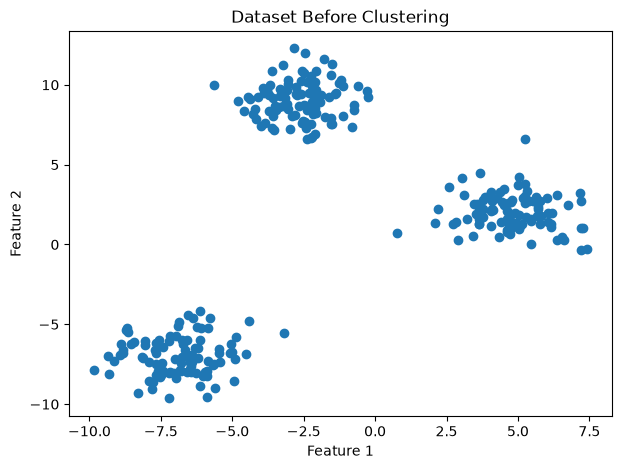

In [12]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset Before Clustering")

plt.show()

In [13]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Before scaling:\n", X[:5])
print("\nAfter scaling:\n", X_scaled[:5])

Before scaling:
 [[-7.43086027 -7.89992284]
 [-7.91212323 -7.34157625]
 [-1.52214373  7.54927375]
 [ 4.37866139  3.29170191]
 [-9.32537663 -8.08981317]]

After scaling:
 [[-1.17808295 -1.38679069]
 [-1.2751755  -1.30311925]
 [ 0.01397294  0.92836   ]
 [ 1.20443274  0.29033844]
 [-1.56029275 -1.41524685]]


In [14]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

In [15]:
labels = kmeans.fit_predict(X_scaled)

print("First 20 cluster labels:")
print(labels[:20])

print("\nCluster centers:")
print(kmeans.cluster_centers_)
print("\nInertia:", kmeans.inertia_)

First 20 cluster labels:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]

Cluster centers:
[[-0.21518875  1.15316649]
 [-1.06790185 -1.25264527]
 [ 1.2830906   0.09947878]]

Inertia: 25.814882630651766


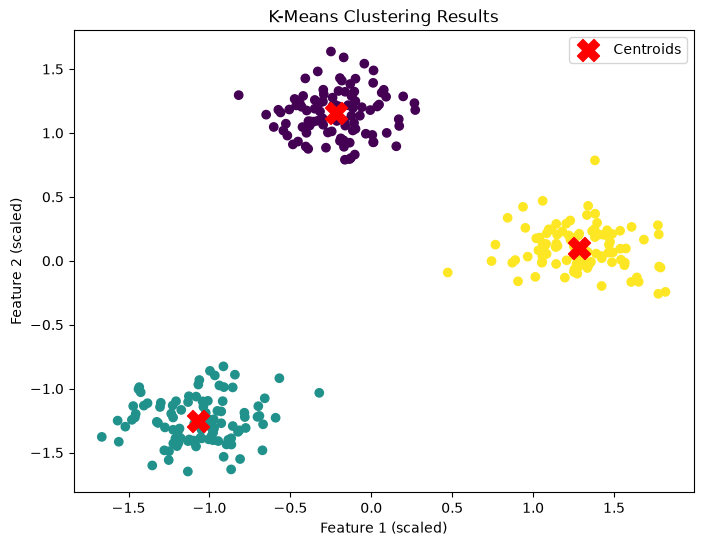

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("K-Means Clustering Results")
plt.legend()
plt.show()

In [17]:
cluster_counts = pd.Series(labels).value_counts().sort_index()

print(cluster_counts)

0    100
1    100
2    100
Name: count, dtype: int64


In [18]:
# Store inertia for different values of K
# also using this for elbow test
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print(wcss)

[600.0, 193.56982177808598, 25.814882630651766, 21.85766451094984, 18.003684232163874, 15.130581016282562, 13.462085906029236, 11.876413605630958, 10.502867011617862, 9.56040524299837]


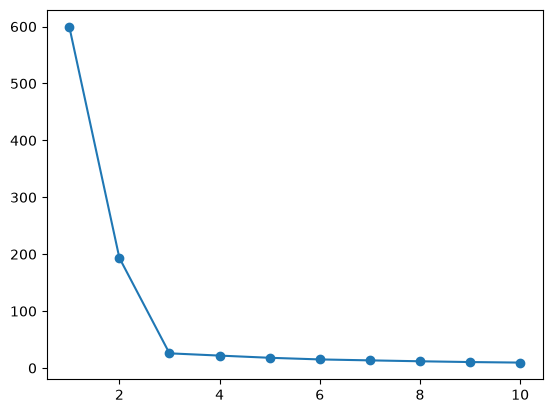

In [19]:
plt.plot(range(1,11),wcss,marker='o')

In [20]:
# silhoutte score 
    #-> cohesion - how close data points to other in its cluster , 
    #-> seperation - how far it is from points in the nearest cluster 

from sklearn.metrics import silhouette_score
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.6712
K = 3, Silhouette Score = 0.8182
K = 4, Silhouette Score = 0.6576
K = 5, Silhouette Score = 0.5077
K = 6, Silhouette Score = 0.3593
K = 7, Silhouette Score = 0.3680
K = 8, Silhouette Score = 0.3666
K = 9, Silhouette Score = 0.3533
K = 10, Silhouette Score = 0.3629


# K-Means Clustering

## 1. What Is Clustering?

Clustering is an unsupervised machine learning technique that groups similar data points together without using predefined target labels.

Examples:
- Customer segmentation
- Grouping similar products
- Document clustering
- Grouping users based on behavior

### Supervised vs. Unsupervised Learning

| Classification | Clustering |
|---|---|
| Supervised learning | Unsupervised learning |
| Uses labeled data | Does not require labels |
| Predicts known classes | Discovers groups in data |
| Example: Spam detection | Example: Customer segmentation |

---

## 2. What Is K-Means?

K-Means is an unsupervised learning algorithm that divides data into `K` clusters based on similarity.

- `K` represents the number of clusters.
- A centroid represents the mean position of the points in a cluster.
- Points are assigned to their nearest centroid.
- Centroids are repeatedly updated until convergence.

K-Means aims to minimize the sum of squared distances between data points and their assigned centroids.

---

## 3. How K-Means Works

1. Choose the number of clusters, `K`.
2. Initialize `K` centroids using an initialization method such as K-Means++.
3. Calculate the distance from each point to each centroid.
4. Assign each point to its nearest centroid.
5. Recalculate each centroid as the mean of its assigned points.
6. Repeat the assignment and centroid-update steps until convergence or the maximum iteration limit is reached.

---

## 4. Euclidean Distance

K-Means commonly uses Euclidean distance to determine the nearest centroid.

For two points $A=(x_1,y_1)$ and $B=(x_2,y_2)$:

$d(A,B)=\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}$

Example:

Point A = (2, 3)

Centroid B = (5, 7)

$d(A,B)=\sqrt{(5-2)^2+(7-3)^2}$

$d(A,B)=\sqrt{9+16}=5$

The point is assigned to the centroid with the smallest distance.

---

## 5. Centroid Calculation

A centroid is calculated by taking the mean of each feature among the points assigned to a cluster.

Suppose a cluster contains three points:

$(2,4), (4,6), (6,8)$

The centroid coordinates are:

$x_c=\frac{2+4+6}{3}=4$

$y_c=\frac{4+6+8}{3}=6$

Therefore, the centroid is $(4,6)$.

---

## 6. Feature Scaling

Feature scaling is important because K-Means uses distance calculations.

Suppose customer data contains:

- Annual spending: values in thousands.
- Monthly purchases: values between 1 and 10.

Without scaling, annual spending may dominate the distance calculation because its numerical values are much larger.

Feature scaling transforms features to comparable scales.

### StandardScaler

Transforms features to approximately zero mean and unit variance.

### MinMaxScaler

Usually transforms features into the range 0 to 1.

### Jupyter Cell: Import StandardScaler

```python
from sklearn.preprocessing import StandardScaler
```

### Jupyter Cell: Scale the features

```python
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

Scaling is performed column-wise, meaning each feature is scaled independently.

Important: Fit the scaler on training data only when working with a train/test workflow, then use that fitted scaler to transform new data.

---

## 7. K-Means++ Initialization

K-Means needs initial centroids before it begins clustering.

K-Means++ chooses initial centroids using a probability-based strategy that encourages them to be spread apart.

Steps:

1. Select the first centroid randomly from the data points.
2. Calculate each point's squared distance from its nearest selected centroid.
3. Select the next centroid probabilistically, giving points farther from existing centroids a higher probability.
4. Repeat until `K` initial centroids have been selected.
5. Run the normal K-Means algorithm.

K-Means++ generally improves initialization compared with ordinary random initialization, but it does not guarantee the globally optimal clustering.

---

## 8. What Is Inertia / WCSS?

Inertia, also called Within-Cluster Sum of Squares (WCSS), measures the sum of squared distances between each point and its assigned centroid.

$WCSS=\sum_{i=1}^{n}\|x_i-\mu_{c_i}\|^2$

Where:

- $x_i$ = data point.
- $\mu_{c_i}$ = centroid of the cluster assigned to that point.
- $n$ = total number of data points.

Example:

Centroid = 5

Data points = 3, 5, 7

$WCSS=(3-5)^2+(5-5)^2+(7-5)^2$

$WCSS=4+0+4=8$

### Interpretation

- Lower inertia generally means points are closer to their assigned centroids.
- Higher inertia means points are farther from their assigned centroids.
- Inertia generally decreases as `K` increases.
- Inertia alone does not tell us whether different clusters are well-separated.

---

## 9. The Elbow Method

The Elbow Method helps estimate a suitable number of clusters by examining how inertia changes as `K` increases.

### Procedure

1. Try multiple values of `K`.
2. Fit a separate K-Means model for each value.
3. Record the inertia for every model.
4. Plot `K` against inertia.
5. Look for the point where the decrease in inertia starts slowing down significantly.

This point is called the elbow.

The elbow suggests a reasonable value of `K`; it does not guarantee that the clusters are well-separated.

### Jupyter Cell: Import libraries

```python
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
```

### Jupyter Cell: Calculate WCSS

```python
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
```

### Jupyter Cell: Plot the Elbow Curve

```python
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid(True)
plt.show()
```

### Interpretation

- X-axis: Number of clusters, `K`.
- Y-axis: Inertia or WCSS.
- Choose a candidate `K` near the point where the curve begins to flatten.

---

## 10. Silhouette Score

Silhouette Score evaluates how well data points fit their own clusters compared with the nearest alternative cluster.

It considers two quantities:

- $a$: Average distance from a point to other points in its own cluster.
- $b$: Lowest average distance from that point to points in another cluster.

The Silhouette Score is:

$s=\frac{b-a}{\max(a,b)}$

### Intuition

If a point is close to its own cluster and far from the nearest other cluster, its score is high.

If it is almost equally close to both clusters, its score is near zero.

If it is closer, on average, to another cluster than its assigned cluster, its score may be negative.

### Score Interpretation

| Silhouette Score | Interpretation |
|---|---|
| Close to +1 | Well-assigned point with good separation |
| Close to 0 | Point near a cluster boundary or overlapping clusters |
| Close to -1 | Point may be assigned to an unsuitable cluster |

The overall Silhouette Score is usually the average of the individual point scores.

### Jupyter Cell: Import Silhouette Score

```python
from sklearn.metrics import silhouette_score
```

### Jupyter Cell: Compare different K values

```python
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")
```

Silhouette Score requires at least two clusters, so we start at `K = 2`.

### Jupyter Cell: Plot Silhouette Scores

```python
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")

plt.xticks(list(k_values))
plt.grid(True)
plt.show()
```

### Jupyter Cell: Find the highest Silhouette Score

```python
best_index = silhouette_scores.index(max(silhouette_scores))
best_k = list(k_values)[best_index]

print("Best K based on Silhouette Score:", best_k)
print("Highest Silhouette Score:", silhouette_scores[best_index])
```

The highest score is a useful candidate, but it does not automatically guarantee the best solution for every problem.

---

## 11. Inertia vs. Silhouette Score

| Inertia / WCSS | Silhouette Score |
|---|---|
| Measures distance from points to their assigned centroids | Uses average distances between data points |
| Measures cluster compactness | Evaluates cohesion and separation |
| Lower is generally preferable for a fixed K | Higher is generally preferable |
| Usually decreases as K increases | Can increase or decrease as K changes |
| Used by the Elbow Method | Used to evaluate and compare clustering quality |

### Remember

- Elbow Method: Helps estimate a suitable number of clusters.
- Silhouette Score: Helps evaluate how well points fit their clusters and how separated the clusters are.

Use both methods along with the problem's requirements.

---

## 12. Important K-Means Hyperparameters

| Parameter | Meaning |
|---|---|
| `n_clusters` | Number of clusters, K |
| `init` | Initial centroid selection method |
| `n_init` | Number of different initializations |
| `max_iter` | Maximum iterations per initialization |
| `random_state` | Makes randomized initialization reproducible |
| `tol` | Convergence tolerance |

### n_init

If `n_init=10`, K-Means runs 10 initializations and retains the result with the lowest inertia.

This reduces the chance of choosing a poor result due to an unlucky initialization.

### max_iter

Specifies the maximum number of iterations for each initialization.

K-Means may stop earlier when its convergence criteria are met.

---

## 13. fit(), predict(), and fit_predict()

| Method | Purpose |
|---|---|
| `fit(X)` | Learns cluster centroids and assignments |
| `predict(X)` | Assigns points to the nearest learned centroid |
| `fit_predict(X)` | Fits the model and returns cluster labels for the input points |

### Jupyter Cell: Fit and predict clusters

```python
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels = kmeans.fit_predict(X_scaled)
```

The output contains cluster IDs such as 0, 1, and 2.

These are arbitrary cluster identifiers, not predefined classes.

### Jupyter Cell: Inspect the model

```python
print("Cluster labels:", labels[:20])
print("Centroids:\n", kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)
print("Iterations:", kmeans.n_iter_)
```

---

## 14. Visualize Clusters

For a dataset with two features, we can visualize clusters on a scatter plot.

### Jupyter Cell: Plot the clusters

```python
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("K-Means Clustering")
plt.legend()
plt.show()
```

Colored points indicate assigned clusters. Red crosses indicate the centroids.

---

## 15. Important K-Means Limitations

1. **Choosing K:** The number of clusters must be specified beforehand.
2. **Outliers:** Extreme points can pull centroids away from dense groups.
3. **Feature scaling:** Features with larger numerical scales can dominate distance calculations.
4. **Cluster shape:** K-Means can struggle with irregularly shaped clusters.
5. **Different densities:** It may struggle when clusters have very different densities or sizes.
6. **Initialization:** Different initial centroids can produce different results.
7. **Cluster interpretation:** Cluster IDs do not have inherent meaning; the groups must be interpreted using the original features.

---

## 16. Other Clustering Evaluation Metrics

| Metric | What it measures | Preferred direction |
|---|---|---|
| Inertia / WCSS | Within-cluster compactness | Lower |
| Silhouette Score | Cohesion and separation | Higher |
| Davies–Bouldin Index | Similarity between clusters based on spread and separation | Lower |
| Calinski–Harabasz Index | Between-cluster dispersion relative to within-cluster dispersion | Higher |
| Adjusted Rand Index (ARI) | Agreement between discovered clusters and known labels | Higher |

ARI can be useful when ground-truth labels are available for evaluation. Those labels are not required for K-Means training.

---

## 17. Complete K-Means Model Selection Workflow

1. Understand the dataset and select relevant features.
2. Handle missing values and prepare the data.
3. Scale features when appropriate.
4. Test several candidate values of K.
5. Record inertia for each model.
6. Plot the Elbow Curve and identify a reasonable candidate.
7. Calculate Silhouette Scores and compare clustering quality.
8. Consider cluster stability, interpretability, and the real-world objective.
9. Train the final K-Means model using the selected K.
10. Visualize and interpret the clusters.

### Final Notes

- K-Means is an unsupervised learning algorithm.
- K-Means++ initializes centroids; it does not choose K.
- Inertia is the same quantity commonly called WCSS in the Elbow Method.
- The Elbow Method helps estimate K; Silhouette Score evaluates cohesion and separation.
- A lower inertia alone does not mean a better clustering.
- Cluster labels are arbitrary and may be numbered differently across runs.

# Next Topic: Hierarchical Clustering

Hierarchical Clustering builds a hierarchy of clusters rather than requiring us to choose a final number of clusters at the beginning in the same way as K-Means.

We will learn:

1. Agglomerative vs. divisive clustering.
2. Euclidean distance and linkage methods.
3. Dendrograms and how to select the number of clusters.
4. Ward linkage, single linkage, complete linkage, and average linkage.
5. Implementation in scikit-learn using separate Jupyter Notebook cells.